# Plant Performance Lab
### Predicting hourly electrical output of a combined cycle power plant

[Open the dashboard](http://localhost:8501) once Streamlit is running.

## 1. Introduction and background
A combined cycle plant uses gas and steam turbines to generate electricity. Its output changes with ambient conditions and operating measurements, even at full load. A plant operator could compare measured generation with an estimate under similar conditions. A persistent difference might justify investigation, but is not proof of a fault.

## 2. Problem statement
The challenge is to estimate net hourly electrical output (PE, in MW) from four measurements: ambient temperature (AT), exhaust vacuum (V), ambient pressure (AP) and relative humidity (RH). The task is supervised regression, not fault detection or automatic control. How accurately can these measurements estimate output on held-out observations from the same plant?

## 3. Objectives
**Main objective:** Develop and evaluate a reproducible model to estimate net hourly electrical output.

**Specific objectives:**
- Inspect data quality, distributions and relationships in the UCI observations.
- Compare Linear Regression, Ridge, Random Forest and Gradient Boosting using five-fold training cross-validation.
- Tune the selected model and report R², RMSE and MAE on held-out test data.
- Identify influential measurements and examine prediction errors.
- Save the fitted model and create an interactive dashboard with a locally grounded assistant.

**Success criteria:** Improve on the linear baseline where possible and report prediction errors in MW. No operational accuracy threshold is assumed without a plant-specific requirement.

First, import the tools and locate the project folder.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().resolve()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src.data import load_data, FEATURES, LABELS
from src.modeling import split_data, compare, tune, diagnostics, save_results
from src.reporting import update_readme
sns.set_theme(style='whitegrid', palette='deep')
fig_dir = root / 'reports/figures'
fig_dir.mkdir(parents=True, exist_ok=True)
def show(fig, name):
    fig.tight_layout()
    fig.savefig(fig_dir / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 4. Data understanding and quality assessment
The UCI Combined Cycle Power Plant dataset contains measurements collected from 2006 to 2011 during full-load operation. The bundled CSV matches the first worksheet of the supplied UCI workbook; the other worksheets are shuffled copies, not additional observations.

| Column | Meaning | Unit | Role |
|---|---|---|---|
| AT | Ambient temperature | °C | Predictor |
| V | Exhaust vacuum | cm Hg | Predictor |
| AP | Ambient pressure | mbar | Predictor |
| RH | Relative humidity | % | Predictor |
| PE | Net hourly electrical output | MW | Target |

Inspect dimensions, types, summary statistics, missing values and duplicate rows. Keep duplicates in the primary analysis because timestamps are absent; check overlap between training and testing. No imputation is needed if the completeness check passes.

In [2]:
df = load_data()
print('Shape:', df.shape)
display(df.head(), df.dtypes, df.describe().T)
print('Missing values:')
display(df.isna().sum())
print('Exact duplicate rows:', df.duplicated().sum())

Shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


Missing values:


AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Exact duplicate rows: 41


## 5. Exploratory data analysis (EDA)
### 5.1 Distributions
Look at the spread of each sensor reading and output before fitting anything. The histograms reveal whether the measurements cluster or cover their ranges evenly.

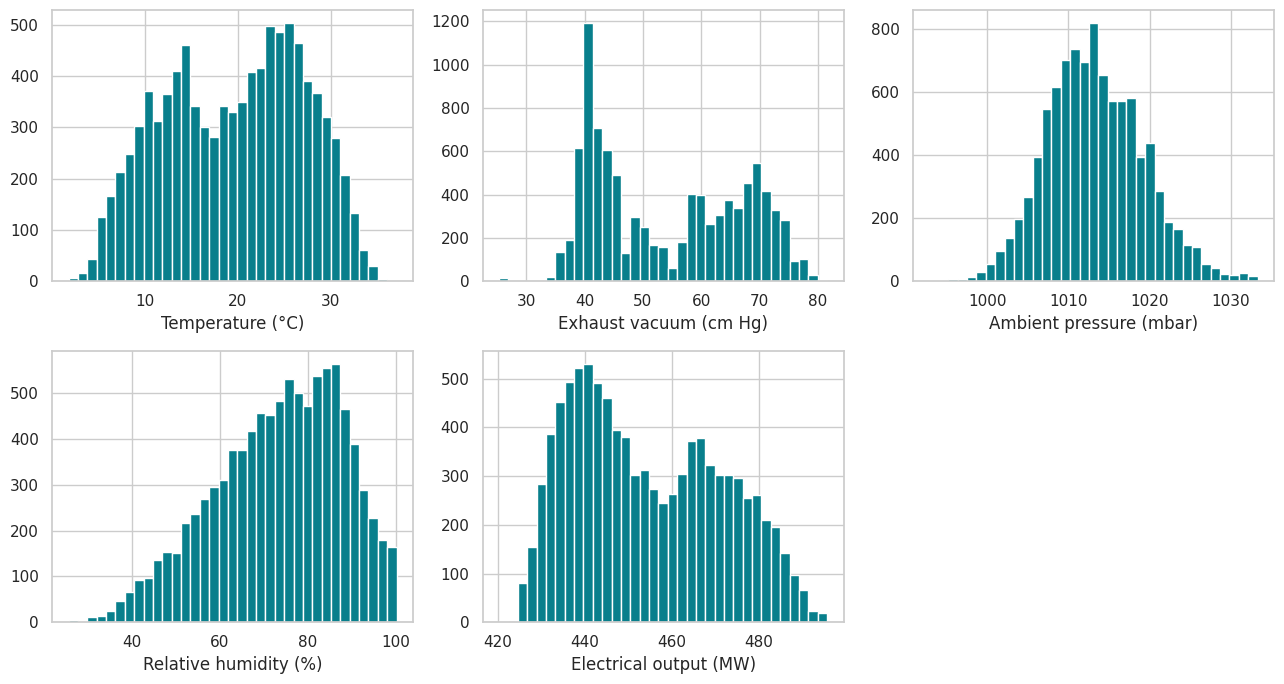

Output ranges from 420.26 to 495.76 MW, with a mean of 454.37 MW.

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, df.columns):
    ax.hist(df[col], bins=35, color="#087F8C", edgecolor="white")
    ax.set_xlabel(LABELS[col])
axes.flat[-1].set_visible(False)
show(fig, 'distributions')
display(Markdown(f"Output ranges from {df.PE.min():.2f} to {df.PE.max():.2f} MW, with a mean of {df.PE.mean():.2f} MW."))

### 5.2 Correlations and feature relationships
The heatmap and scatter plots show how the four inputs relate to output. A straight-line trend is useful for orientation, but it does not establish a causal relationship.

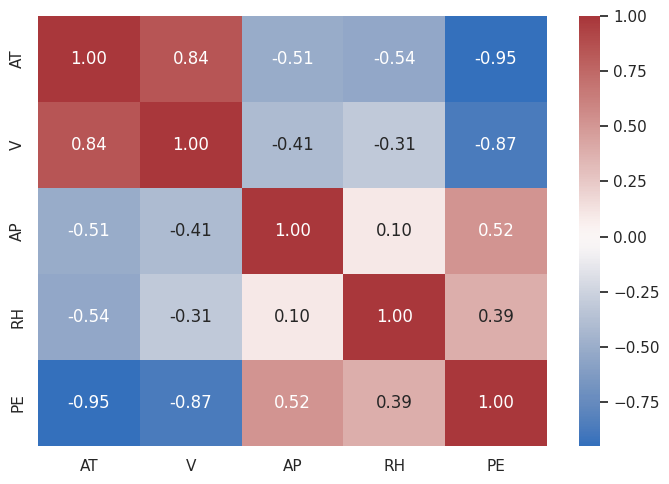

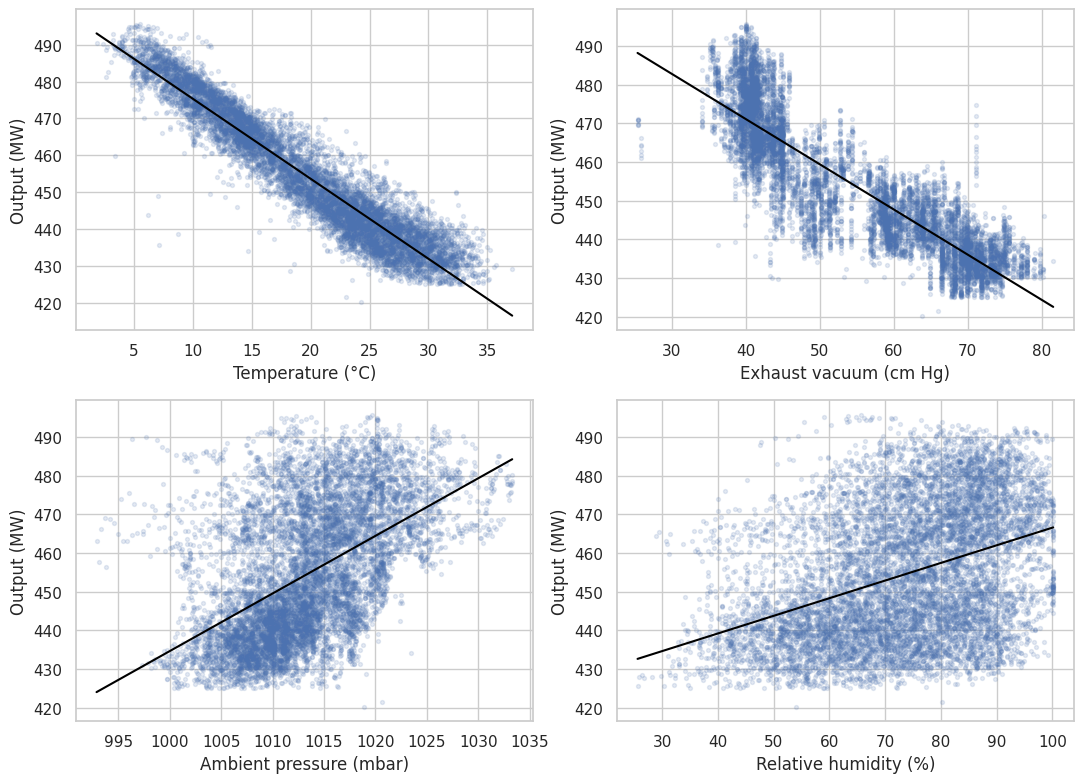

Temperature (°C): correlation -0.948. Output tends to fall as this reading increases.
Exhaust vacuum (cm Hg): correlation -0.870. Output tends to fall as this reading increases.
Ambient pressure (mbar): correlation +0.518. Output tends to rise as this reading increases.
Relative humidity (%): correlation +0.390. Output tends to rise as this reading increases.


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax)
show(fig, 'correlation')
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.flat, FEATURES):
    ax.scatter(df[f], df.PE, alpha=.15, s=8)
    x_line = np.array([df[f].min(), df[f].max()])
    ax.plot(x_line, np.polyval(np.polyfit(df[f], df.PE, 1), x_line), color='black')
    ax.set_xlabel(LABELS[f])
    ax.set_ylabel('Output (MW)')
show(fig, 'feature_relationships')
for f in FEATURES:
    r = df[f].corr(df.PE)
    print(f'{LABELS[f]}: correlation {r:+.3f}. ' + ('Output tends to rise' if r > 0 else 'Output tends to fall') + ' as this reading increases.')

## 6. Data preparation and train/test split
Reserve 20% for test evaluation. Each candidate contains its own StandardScaler, fitted only on the training portion of each fold. The random split is reproducible but cannot establish chronological generalization.

In [5]:
split = split_data(df)
x_train, x_test, y_train, y_test = split
print('Training:', x_train.shape, 'Testing:', x_test.shape)
# Count test rows identical to a training observation.
train_rows = x_train.assign(PE=y_train).drop_duplicates()
test_rows = x_test.assign(PE=y_test)
overlap = test_rows.merge(train_rows, on=FEATURES + ['PE'], how='inner')
print('Exact test observations also present in training:', len(overlap))

Training: (7654, 4) Testing: (1914, 4)
Exact test observations also present in training: 14


## 7. Model development and evaluation
Linear Regression is the baseline. Ridge adds regularization, while Random Forest and Gradient Boosting can capture nonlinear relationships. Five-fold CV on training data decides which family to tune. Test metrics are reported for context only; do not use them to select the model.

R² describes the fraction of variation accounted for. RMSE penalizes larger errors, while MAE reports the average absolute miss. Both errors are measured in MW.

,Model,CV RMSE,CV SD,R2,RMSE,MAE
0,Random Forest,3.4605,0.1526,0.9637,3.2460,2.3298
1,Gradient Boosting,3.9215,0.1101,0.9495,3.8288,2.9489
2,Linear Regression,4.5721,0.0802,0.9301,4.5026,3.5959
3,Ridge,4.5721,0.0802,0.9301,4.5025,3.5959


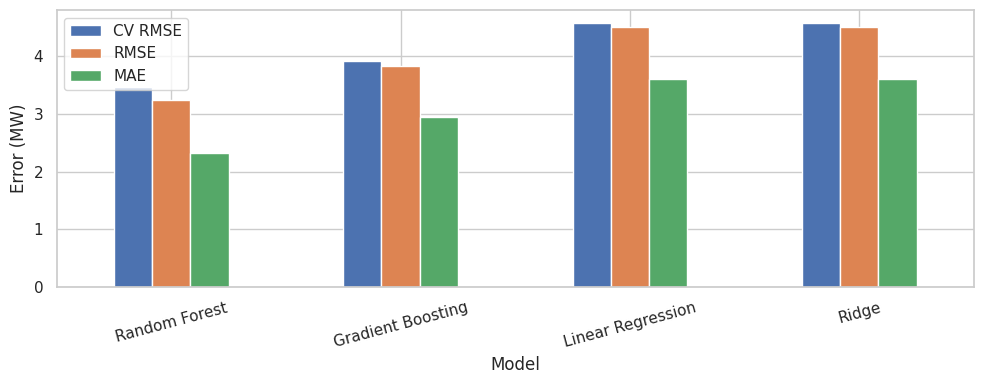

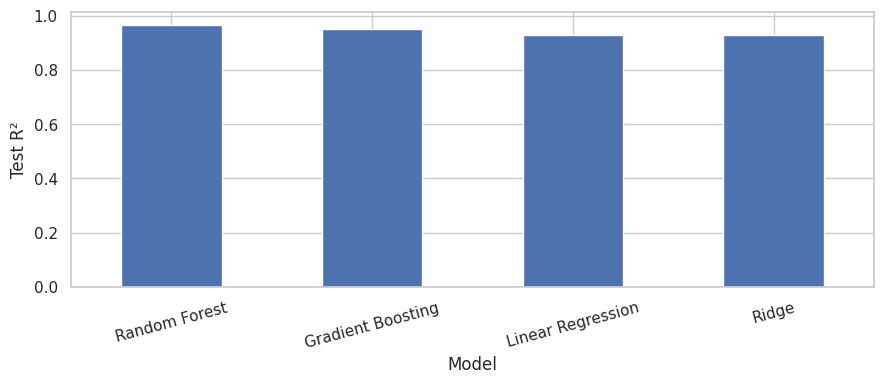

In [6]:
comparison = compare(split)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
comparison.set_index('Model')[['CV RMSE', 'RMSE', 'MAE']].plot.bar(ax=ax, rot=15)
ax.set_ylabel('Error (MW)')
show(fig, 'model_comparison')
fig, ax = plt.subplots(figsize=(9, 4))
comparison.set_index('Model')['R2'].plot.bar(ax=ax, rot=15)
ax.set_ylabel('Test R²')
show(fig, 'model_r2')

## 8. Hyperparameter tuning
Try a small grid for the selected family. Keep the search modest so the project can run on a normal laptop. The test set is not passed into the grid search.

In [7]:
winner = comparison.iloc[0]['Model']
search = tune(split, winner)
print('Selected:', winner)
print('Best parameters:', search.best_params_)
print('Tuned CV RMSE:', -search.best_score_)

Selected: Random Forest
Best parameters: {'model__min_samples_leaf': 1, 'model__n_estimators': 160}
Tuned CV RMSE: 3.45560036162628


## 9. Model interpretation and diagnostics
Plot predicted versus actual output and the residuals. Compare the model's native importance (absolute standardized coefficients for linear models) with held-out permutation importance, which measures how much prediction error increases when a feature is shuffled.

,Feature,Permutation RMSE increase,Native importance
0,AT,17.856382,0.901534
1,V,3.113350,0.062001
2,AP,0.880782,0.018346
3,RH,0.910190,0.018119


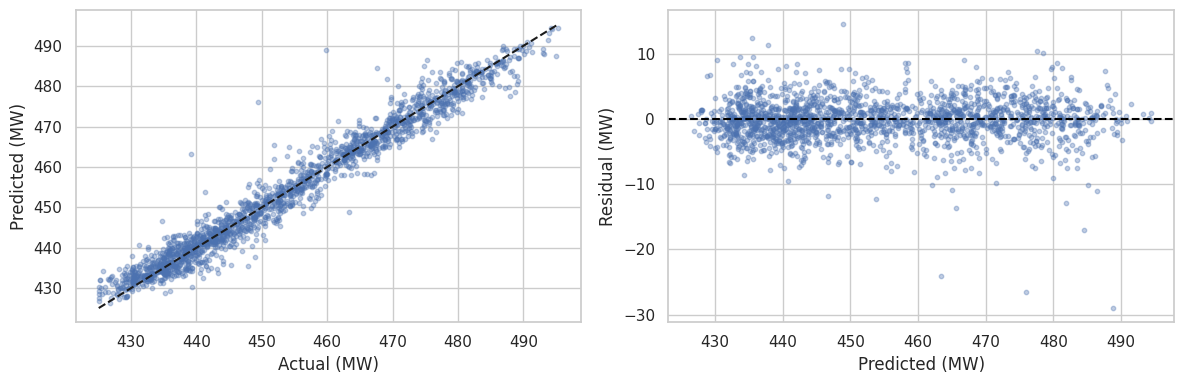

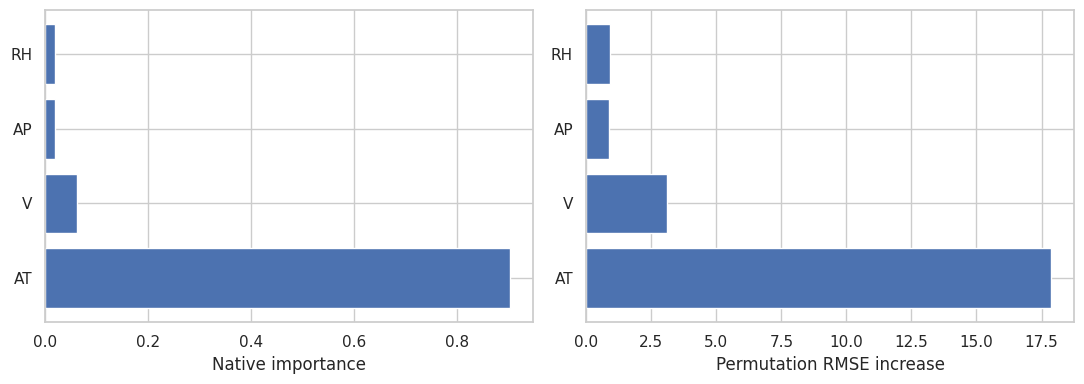

In [8]:
importance, pairs = diagnostics(split, search.best_estimator_)
display(importance)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pairs.Actual, pairs.Predicted, alpha=.35, s=10)
axes[0].set(xlabel='Actual (MW)', ylabel='Predicted (MW)')
lo, hi = pairs.Actual.min(), pairs.Actual.max()
axes[0].plot([lo, hi], [lo, hi], 'k--')
axes[1].scatter(pairs.Predicted, pairs.Residual, alpha=.35, s=10)
axes[1].set(xlabel='Predicted (MW)', ylabel='Residual (MW)')
axes[1].axhline(0, color='black', linestyle='--')
show(fig, 'prediction_diagnostics')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['Native importance', 'Permutation RMSE increase']):
    ax.barh(importance.Feature, importance[col])
    ax.set_xlabel(col)
show(fig, 'importance')

## 10. Conclusion, limitations and deployment
Save the fitted pipeline, comparison, predictions and importance for the dashboard. Generate the conclusion from actual results rather than typing guessed scores. A random split can overstate performance when nearby or duplicate measurements are related. The data covers one full-load plant and does not support generalization to other equipment. Next steps would include time-based validation, external testing and uncertainty estimates.

In [9]:
metrics = save_results(df, comparison, search, winner, importance, pairs)
display(pd.Series(metrics))
display(Markdown(update_readme(df, comparison, metrics, importance)))

model                                             Random Forest
parameters    {'model__min_samples_leaf': 1, 'model__n_estim...
CV RMSE                                                  3.4556
R2                                                     0.963898
RMSE                                                    3.23601
MAE                                                     2.32132
dtype: object

I worked with 9,568 records. Average output was 454.37 MW, and the temperature-output correlation was -0.948. The linear baseline had a test RMSE of 4.50 MW. After selecting and tuning Random Forest using training cross-validation, the final test RMSE was 3.24 MW, MAE was 2.32 MW and R² was 0.9639. The largest permutation importance belonged to AT, with a 17.86 MW increase in error when shuffled. That is a measure of model dependence, not a causal effect.

## 11. Recommendations and future work
Collect timestamped observations for chronological validation. Repeat the analysis with duplicate observations kept together to assess possible leakage. Validate at other plants and at part load. Add uncertainty estimates and evaluate the dashboard with operators before operational use.

## References
Tufekci, P. & Kaya, H. (2014). *Combined Cycle Power Plant*. UCI Machine Learning Repository. [https://doi.org/10.24432/C5002N](https://doi.org/10.24432/C5002N). CC BY 4.0.